# 070 CASE 010 — Getting started: spectral indices on Gotland

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** What does one Sentinel-2 scene look like, and how do you compute vegetation and water indices on it?

**Area:** North-west Gotland around Visby, 21 June 2024.

**Partners:** RISE, AI Sweden, Luleå University of Technology, Swedish National Space Agency

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Copernicus Sentinel-2 data are free and open.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus the plotting libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1a" folium matplotlib
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own
DES account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password. The login is yours: no credentials are shared or saved in the notebook. Without a login the data fetch stops with an error; there is no synthetic
fallback, so every figure comes from real Sentinel-2 data. A run takes about a minute on a laptop CPU.

## Log in to Digital Earth Sweden

In [ ]:
import os
from getpass import getpass

import openeo

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked (never saved in the notebook)
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    os.environ["DES_USER"] = input("DES username: ")
    os.environ["DES_PASSWORD"] = getpass("DES password: ")
    des.authenticate_basic(os.environ["DES_USER"], os.environ["DES_PASSWORD"])
else:
    des.authenticate_oidc(provider_id="egi")  # rerun this cell when the session expires


def des_token():
    """Your EGI login's access token; with a password login IMINT Engine reads DES_USER/DES_PASSWORD."""
    return des.auth.bearer.split("/", 2)[2] if LOGIN_METHOD == "egi" else None


## 1. Method

```
AOI + date → fetch_des_data (DES openEO, Sentinel-2 L2A, SCL cloud mask) → SpectralAnalyzer → plots
```

Every case notebook follows the same skeleton: define the area, fetch real data, run one or more
IMINT Engine analyzers, and show the results. `SpectralAnalyzer` computes NDVI, NDWI, NDBI, EVI and NBR.

## 2. Area and data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud, token=des_token())
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene

AOI = {"west": 18.25, "south": 57.55, "east": 18.45, "north": 57.68}  # Visby, Gotland
DATE = "2024-06-21"

scene = load_scene(DATE, AOI)

    [DES] openEO api=1.1.0 url=https://openeo.digitalearth.se/


    Cloud fraction: 0.0%
2024-06-21: 11 bands, 1507 x 1266 px at 10 m, cloud 0.0% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=11, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#ff7800", weight=2, fill=False, popup=f"AOI · {DATE}",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. Run the spectral analyzer

In [4]:
from imint.analyzers.spectral import SpectralAnalyzer

spectral = SpectralAnalyzer().run(rgb=scene.rgb, bands=scene.bands, date=DATE, coords=AOI,
                                  output_dir="outputs/010", scl=scene.scl, geo=scene.geo)
print(spectral.summary())
indices = spectral.outputs["indices"]
for name, arr in indices.items():
    print(f"{name:5s} median {np.nanmedian(arr):+.3f}  (5th–95th pct {np.nanpercentile(arr, 5):+.3f} … {np.nanpercentile(arr, 95):+.3f})")

[spectral] OK — outputs: indices


NDVI  median +0.732  (5th–95th pct -0.305 … +0.890)
NDWI  median -0.675  (5th–95th pct -0.803 … +0.668)
NDBI  median -0.239  (5th–95th pct -0.478 … +0.100)
EVI   median +0.420  (5th–95th pct -0.011 … +0.692)
NBR   median +0.473  (5th–95th pct -0.033 … +0.719)


## 4. Results

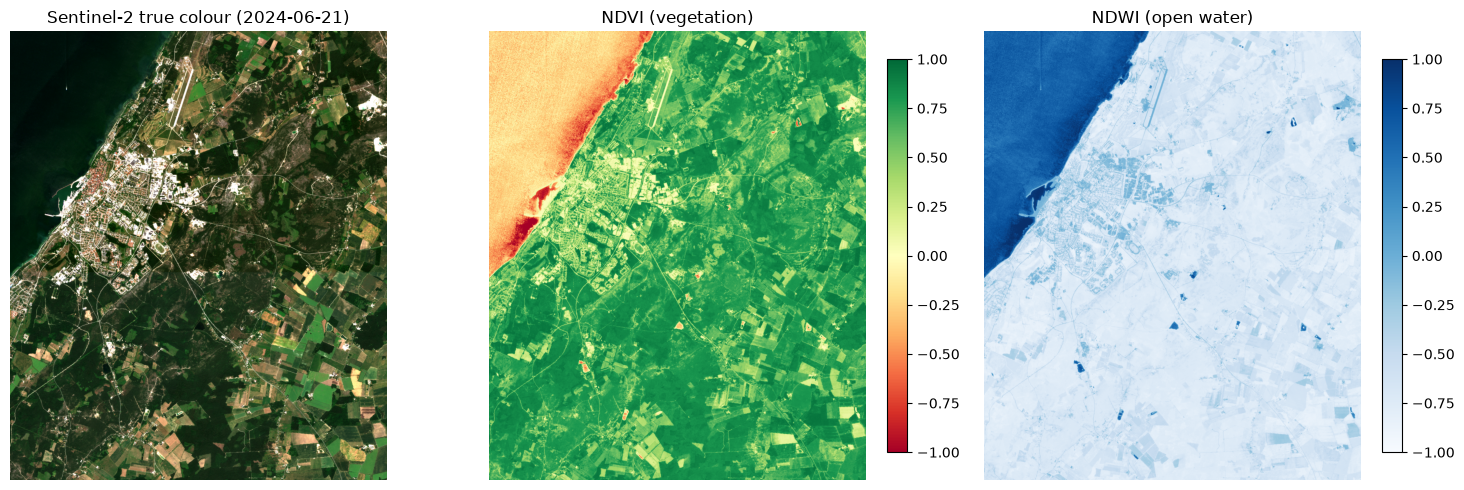

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(scene.rgb)
axes[0].set_title(f"Sentinel-2 true colour ({DATE})")
im1 = axes[1].imshow(indices["NDVI"], cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("NDVI (vegetation)")
im2 = axes[2].imshow(indices["NDWI"], cmap="Blues", vmin=-1, vmax=1)
axes[2].set_title("NDWI (open water)")
for ax in axes:
    ax.axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046)
fig.colorbar(im2, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

## 5. Interpretation and next steps

High NDVI marks farmland and forest inland; the sea and Visby's built-up area have low or negative NDVI,
and NDWI separates open water from land. To build your own case, copy this notebook, change `AOI` and
`DATE`, and swap in another analyzer from [`imint/analyzers`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers).

**Links:** [`imint/fetch.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/fetch.py) ·
[`imint/analyzers/spectral.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/spectral.py)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).